# Cyclistic: Statistik Deskriptif dan Uji Hipotesis (Bagian 5.1 dan 5.2)

Notebook ini membaca **Silver Parquet** (data bersih per perjalanan) dan menghasilkan:
1. **Statistik deskriptif** casual vs member (bahan bagian 5.1 dan dasar merumuskan hipotesis).
2. **Uji tiga hipotesis** beserta ukuran besar selisihnya (bahan bagian 5.2).
3. File hasil di `output/hipotesis/` yang bisa ditempel ke laporan.

**Urutan kerja yang benar:** jalankan bagian 3 (statistik deskriptif) dulu, baca polanya, baru putuskan hipotesis final di bagian 4.
Tiga hipotesis di bawah adalah **kandidat**. Tim boleh mengganti atau menyempurnakannya setelah melihat hasil eksplorasi sendiri.

**Catatan penting tentang data besar.** Dengan jutaan baris, selisih sekecil apa pun menghasilkan p-value mendekati nol.
Karena itu keputusan tidak hanya memakai p-value, tetapi juga **besar selisih** (selisih proporsi, median, ukuran efek) dan interval kepercayaannya.

## 1. Konfigurasi

In [1]:
from pathlib import Path

PARQUET_PATH = Path("data/silver")
OUTPUT_DIR = Path("output/hipotesis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ALPHA = 0.05                   # taraf signifikansi keseluruhan
N_HIPOTESIS = 3                # untuk koreksi Bonferroni (alpha dibagi jumlah uji)
RANDOM_STATE = 42

# Definisi hipotesis (ubah bila tim merumuskan hal lain setelah melihat statistik deskriptif)
WARM_MONTHS = [5, 6, 7, 8, 9]  # bulan hangat (H3)
COLD_MONTHS = [12, 1, 2]       # bulan dingin (H3)
WEEKEND_DOW = [5, 6]           # 5 = Sabtu, 6 = Minggu (H1)

# Bootstrap untuk selisih median (H2)
BOOT_SAMPLE = 200_000
BOOT_REPS = 500

# Zona waktu: Silver menyimpan started_at dalam UTC, sedangkan data Divvy aslinya waktu lokal Chicago.
SILVER_TZ = "UTC"              # zona waktu penyimpanan started_at di Silver. Isi None bila sudah waktu lokal
LOCAL_TZ = "America/Chicago"   # zona waktu asli data Divvy

SAMPLE_FRAC = None             # isi 0.2 untuk uji coba cepat

## 2. Memuat data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.dataset as ds
from scipy import stats

pd.set_option("display.width", 150)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

COLS = ["member_casual", "rideable_type", "started_at", "trip_duration_minutes", "is_false_start", "is_outlier_24h"]

dataset = ds.dataset(str(PARQUET_PATH), format="parquet")
missing = [c for c in COLS if c not in dataset.schema.names]
if missing:
    raise KeyError(f"Kolom tidak ditemukan di Silver: {missing}. Kolom yang ada: {dataset.schema.names}")

table = dataset.to_table(columns=COLS)
for i, field in enumerate(table.schema):
    if pa.types.is_string(field.type) or pa.types.is_large_string(field.type):
        table = table.set_column(i, field.name, pc.dictionary_encode(table[field.name]))
raw = table.to_pandas()
print(f"Baris di Silver: {len(raw):,}")

# Trip yang ditandai kotor di Silver dikeluarkan (sama dengan dasbor)
flagged = raw["is_false_start"].fillna(False).astype(bool) | raw["is_outlier_24h"].fillna(False).astype(bool)
df = raw.loc[~flagged].copy()
print(f"Dikeluarkan (false start / lebih dari 24 jam): {flagged.sum():,} | dipakai: {len(df):,}")

df["started_at"] = pd.to_datetime(df["started_at"])
if SILVER_TZ:   # ubah UTC -> waktu lokal Chicago sebelum menurunkan jam, hari, dan bulan
    df["started_at"] = df["started_at"].dt.tz_localize(SILVER_TZ).dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
df["dow"] = df["started_at"].dt.dayofweek.astype("int8")
df["hour"] = df["started_at"].dt.hour.astype("int8")
df["month"] = df["started_at"].dt.month.astype("int8")
df["year_month"] = (df["started_at"].dt.year * 100 + df["started_at"].dt.month).astype("int32")
df["is_weekend"] = df["dow"].isin(WEEKEND_DOW)
df["is_casual"] = (df["member_casual"] == "casual")
df["duration"] = df["trip_duration_minutes"].astype("float64")
df = df.drop(columns=["started_at", "trip_duration_minutes", "is_false_start", "is_outlier_24h"])

if SAMPLE_FRAC:
    df = df.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE).reset_index(drop=True)
    print("Mode sampel (hanya uji coba):", f"{len(df):,}")
print("Periode (bulan):", df["year_month"].min(), "sampai", df["year_month"].max())

# Pemeriksaan zona waktu: di Chicago, jam tersibuk member biasanya sekitar jam 16-18 (pulang kerja)
top_hours = df[df["member_casual"] == "member"]["hour"].value_counts().head(3).index.tolist()
print("Jam tersibuk member:", top_hours, "(harapan: sekitar 16-18 untuk waktu lokal Chicago)")
if not set(top_hours) & {16, 17, 18}:
    print("PERINGATAN: jam puncak tidak sesuai harapan. Periksa pengaturan SILVER_TZ dan LOCAL_TZ.")
print("Bulan di luar April 2021 - Maret 2022:", df.loc[~df["year_month"].between(202104, 202203), "year_month"].value_counts().to_dict())
df.head()

Baris di Silver: 5,722,346
Dikeluarkan (false start / lebih dari 24 jam): 93,229 | dipakai: 5,629,117


C:\Users\fbrnt\AppData\Local\Temp\ipykernel_29464\2385204015.py:34: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dow"] = df["started_at"].dt.dayofweek.astype("int8")


Periode (bulan): 202104 sampai 202203
Jam tersibuk member: [17, 18, 16] (harapan: sekitar 16-18 untuk waktu lokal Chicago)
Bulan di luar April 2021 - Maret 2022: {}


,member_casual,rideable_type,dow,hour,month,year_month,is_weekend,is_casual,duration
0,member,classic_bike,2,8,4,202104,False,False,9.0500
1,casual,docked_bike,4,13,4,202104,False,True,19.1700
2,member,electric_bike,4,6,4,202104,False,False,14.2300
3,member,classic_bike,6,14,4,202104,True,False,13.0200
4,member,electric_bike,0,13,4,202104,False,False,8.7200


## 3. Statistik deskriptif (bagian 5.1)

Baca hasil di bawah **sebelum** menetapkan hipotesis. Pola yang tampak di sini adalah dasar (alasan) setiap hipotesis di laporan.

In [3]:
desc = {}

# Jumlah dan porsi
cnt = df["member_casual"].value_counts()
desc["jumlah_trip"] = cnt
print("Jumlah trip per tipe:\n", cnt, "\n")

# Durasi
dur = df.groupby("member_casual", observed=True)["duration"].agg(
    n="size", rata_rata="mean", median="median", persentil_25=lambda x: x.quantile(.25),
    persentil_75=lambda x: x.quantile(.75), persentil_90=lambda x: x.quantile(.90),
    persen_lebih_60_menit=lambda x: (x > 60).mean() * 100)
desc["durasi_menit"] = dur
print("Durasi (menit):\n", dur, "\n")

# Akhir pekan
wk = df.groupby("member_casual", observed=True)["is_weekend"].mean().mul(100).rename("persen_trip_akhir_pekan")
desc["akhir_pekan"] = wk.to_frame()
print("Porsi trip akhir pekan (%):\n", wk, "\n")

# Jenis sepeda
bike = pd.crosstab(df["rideable_type"], df["member_casual"], normalize="columns").mul(100)
desc["jenis_sepeda_persen"] = bike
print("Jenis sepeda (% dalam kelompok):\n", bike, "\n")

# Porsi casual per bulan
by_month = df.groupby("year_month")["is_casual"].agg(trip="size", casual="sum")
by_month["persen_casual"] = by_month["casual"] / by_month["trip"] * 100
desc["porsi_casual_per_bulan"] = by_month
print("Porsi casual per bulan:\n", by_month, "\n")

for name, tbl in desc.items():
    tbl.to_csv(OUTPUT_DIR / f"deskriptif_{name}.csv")
print("Tabel deskriptif tersimpan di", OUTPUT_DIR)

Jumlah trip per tipe:
 member_casual
member    3121568
casual    2507549
Name: count, dtype: int64 

Durasi (menit):
                      n  rata_rata  median  persentil_25  persentil_75  persentil_90  persen_lebih_60_menit
member_casual                                                                                             
member         3121568    13.3582  9.5300        5.6200       16.4000       26.4700                 0.7668
casual         2507549    26.8644 15.9800        9.1700       29.1000       54.7300                 8.6351 

Porsi trip akhir pekan (%):
 member_casual
member   25.7380
casual   40.5501
Name: persen_trip_akhir_pekan, dtype: float64 

Jenis sepeda (% dalam kelompok):
 member_casual  member  casual
rideable_type                
classic_bike  62.8896 49.5316
docked_bike    0.0000 11.9905
electric_bike 37.1104 38.4779 

Porsi casual per bulan:
               trip  casual  persen_casual
year_month                               
202104      332142  134713      

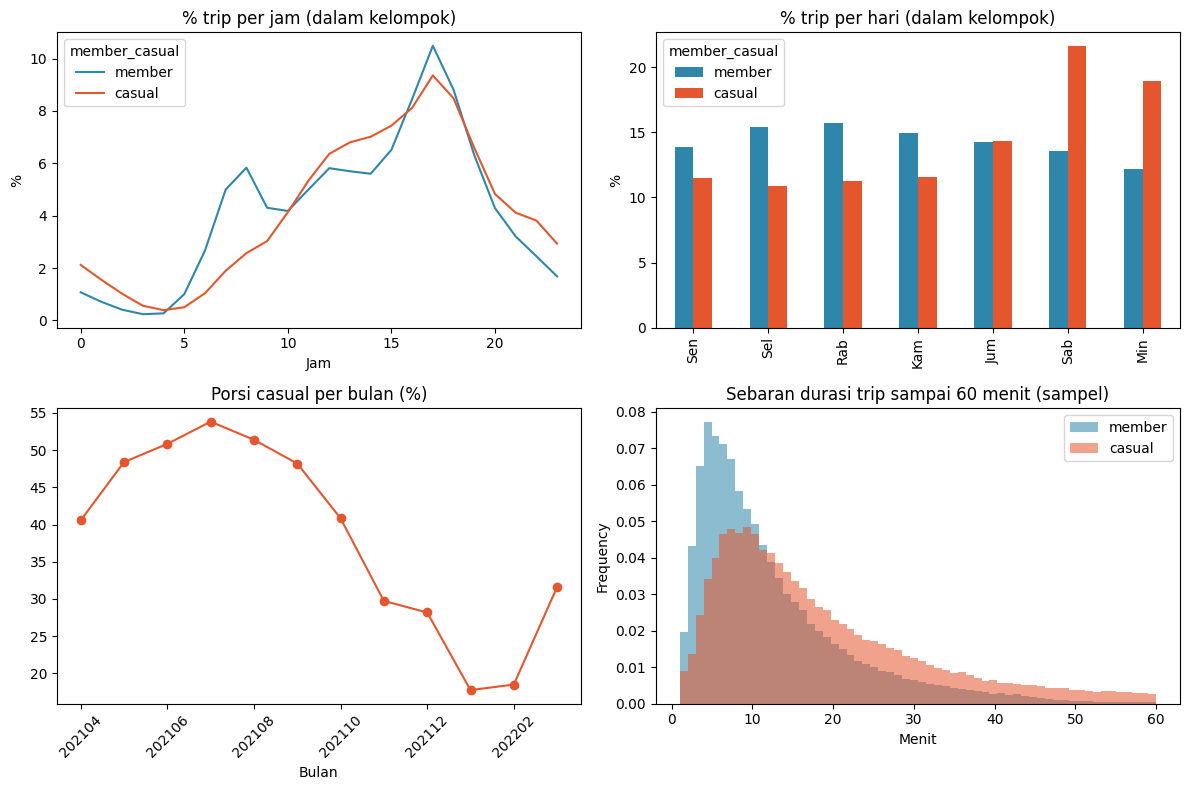

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
colors = {"casual": "#E4572E", "member": "#2E86AB"}

hour = df.groupby(["hour", "member_casual"], observed=True).size().unstack(fill_value=0)
(hour / hour.sum() * 100).plot(ax=ax[0, 0], color=colors, title="% trip per jam (dalam kelompok)", xlabel="Jam", ylabel="%")

day = df.groupby(["dow", "member_casual"], observed=True).size().unstack(fill_value=0)
(day / day.sum() * 100).set_axis(["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"]).plot.bar(
    ax=ax[0, 1], color=colors, title="% trip per hari (dalam kelompok)", ylabel="%")

by_month["persen_casual"].set_axis(by_month.index.astype(str)).plot(ax=ax[1, 0], marker="o", rot=45, color=colors["casual"], title="Porsi casual per bulan (%)", xlabel="Bulan")

sample = df.sample(n=min(300_000, len(df)), random_state=RANDOM_STATE)
for u, g in sample.groupby("member_casual", observed=True):
    g.loc[g["duration"] <= 60, "duration"].plot.hist(ax=ax[1, 1], bins=60, alpha=.55, density=True, color=colors[u], label=u)
ax[1, 1].set_title("Sebaran durasi trip sampai 60 menit (sampel)"); ax[1, 1].set_xlabel("Menit"); ax[1, 1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "statistik_deskriptif.png", dpi=150)
plt.show()

## 4. Rumusan hipotesis (bagian 5.2)

Tiga **kandidat** hipotesis. Sebelum dipakai di laporan, tim memastikan masing-masing memang didukung pola di bagian 3 dan menulis alasannya
(kolom "Dasar dari eksplorasi" di laporan).

| | H0 | H1 | Menjawab pertanyaan | Uji |
|---|---|---|---|---|
| **H1** | Proporsi perjalanan di akhir pekan casual = member | Proporsi akhir pekan casual **lebih besar** dari member | Pertanyaan 2 (kapan) | Uji proporsi dua sampel (satu arah) |
| **H2** | Distribusi durasi casual dan member sama | Durasi casual cenderung **lebih panjang** dari member | Pertanyaan 1 (durasi) | Mann-Whitney U (satu arah), karena durasi miring |
| **H3** | Porsi casual di bulan hangat = bulan dingin | Porsi casual di bulan hangat **lebih besar** | Pertanyaan 2 (bulan) | Uji proporsi dua sampel (satu arah) |

Arah (lebih besar) hanya dipakai bila eksplorasi di bagian 3 memang menunjukkan arah itu. Kalau polanya berlawanan, ubah arah atau rumuskan ulang, dan jelaskan alasannya.

**Koreksi uji berganda:** karena ada tiga uji, keputusan memakai Bonferroni, yaitu p-value dibandingkan dengan `ALPHA / N_HIPOTESIS`.

**Asumsi dan keterbatasan:** perjalanan dari orang yang sama tidak independen (data anonim, tidak bisa dikendalikan). Nilai p karenanya cenderung terlalu kecil. Itu sebabnya besar selisih dan interval kepercayaan ikut dilaporkan.

## 5. Fungsi uji

In [5]:
ALPHA_ADJ = ALPHA / N_HIPOTESIS

def fmt_p(p):
    return "< 1e-300" if p < 1e-300 else f"{p:.3g}"

def label_h(h):
    a = abs(h)
    return "sangat kecil" if a < 0.2 else "kecil" if a < 0.5 else "sedang" if a < 0.8 else "besar"

def label_cles(c):
    d = abs(c - 0.5) + 0.5
    return "sangat kecil" if d < 0.56 else "kecil" if d < 0.64 else "sedang" if d < 0.71 else "besar"

def two_prop_test(x1, n1, x2, n2, alternative="greater"):
    """Uji proporsi dua sampel (z, pooled). x = jumlah 'sukses', n = ukuran sampel."""
    p1, p2 = x1 / n1, x2 / n2
    pp = (x1 + x2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
    p = stats.norm.sf(z) if alternative == "greater" else 2 * stats.norm.sf(abs(z))
    diff = p1 - p2
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    h = 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))   # Cohen's h
    return dict(p1=p1, p2=p2, z=z, p=p, diff=diff, ci=(diff - 1.96 * se, diff + 1.96 * se), h=h)

def mann_whitney(a, b, alternative="greater"):
    """a = kelompok yang diduga lebih besar. Mengembalikan U, p, CLES, rank-biserial."""
    res = stats.mannwhitneyu(a, b, alternative=alternative, use_continuity=False, method="asymptotic")
    cles = res.statistic / (len(a) * len(b))     # P(a > b) + 0.5 * P(a = b)
    return dict(U=res.statistic, p=res.pvalue, cles=cles, rank_biserial=2 * cles - 1)

def bootstrap_median_diff(a, b, reps=BOOT_REPS, n=BOOT_SAMPLE, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    a = np.asarray(a); b = np.asarray(b)
    diffs = np.empty(reps)
    for i in range(reps):
        diffs[i] = np.median(rng.choice(a, size=min(n, len(a)))) - np.median(rng.choice(b, size=min(n, len(b))))
    return np.percentile(diffs, [2.5, 97.5])

def run_all(d, populasi):
    rows = []
    cas, mem = d[d["is_casual"]], d[~d["is_casual"]]

    # H1: porsi akhir pekan
    r = two_prop_test(cas["is_weekend"].sum(), len(cas), mem["is_weekend"].sum(), len(mem))
    rows.append({
        "Populasi": populasi, "Hipotesis": "H1: porsi trip akhir pekan casual > member", "Uji": "Uji proporsi dua sampel",
        "Kelompok 1": "casual", "Kelompok 2": "member", "n 1": len(cas), "n 2": len(mem), "Statistik": f"z = {r['z']:.2f}", "p-value": r["p"],
        "Nilai 1": f"{r['p1']*100:.2f}%", "Nilai 2": f"{r['p2']*100:.2f}%",
        "Besar selisih": f"{r['diff']*100:.2f} poin persen (CI 95%: {r['ci'][0]*100:.2f} s.d. {r['ci'][1]*100:.2f})",
        "Ukuran efek": f"Cohen's h = {r['h']:.2f} ({label_h(r['h'])})",
    })

    # H2: durasi
    a, b = cas["duration"].to_numpy(), mem["duration"].to_numpy()
    mw = mann_whitney(a, b)
    ci = bootstrap_median_diff(a, b)
    md_a, md_b = np.median(a), np.median(b)
    rows.append({
        "Populasi": populasi, "Hipotesis": "H2: durasi casual > member", "Uji": "Mann-Whitney U (satu arah)",
        "Kelompok 1": "casual", "Kelompok 2": "member", "n 1": len(a), "n 2": len(b), "Statistik": f"U = {mw['U']:.3e}", "p-value": mw["p"],
        "Nilai 1": f"median {md_a:.1f} menit", "Nilai 2": f"median {md_b:.1f} menit",
        "Besar selisih": f"selisih median {md_a - md_b:.1f} menit (bootstrap CI 95%: {ci[0]:.1f} s.d. {ci[1]:.1f})",
        "Ukuran efek": f"CLES = {mw['cles']:.3f}, rank-biserial = {mw['rank_biserial']:.3f} ({label_cles(mw['cles'])})",
    })

    # H3: porsi casual bulan hangat vs dingin
    warm, cold = d[d["month"].isin(WARM_MONTHS)], d[d["month"].isin(COLD_MONTHS)]
    r = two_prop_test(warm["is_casual"].sum(), len(warm), cold["is_casual"].sum(), len(cold))
    rows.append({
        "Populasi": populasi, "Hipotesis": "H3: porsi casual bulan hangat > bulan dingin", "Uji": "Uji proporsi dua sampel",
        "Kelompok 1": "bulan hangat", "Kelompok 2": "bulan dingin", "n 1": len(warm), "n 2": len(cold),
        "Statistik": f"z = {r['z']:.2f}", "p-value": r["p"],
        "Nilai 1": f"{r['p1']*100:.2f}% casual", "Nilai 2": f"{r['p2']*100:.2f}% casual",
        "Besar selisih": f"{r['diff']*100:.2f} poin persen (CI 95%: {r['ci'][0]*100:.2f} s.d. {r['ci'][1]*100:.2f})",
        "Ukuran efek": f"Cohen's h = {r['h']:.2f} ({label_h(r['h'])})",
    })
    return rows

## 6. Menjalankan uji

Dua populasi dijalankan: **semua data**, dan **tanpa `docked_bike`** sebagai analisis sensitivitas. Tipe `docked_bike` hanya dipakai casual dan bisa memengaruhi hasil durasi.
Kalau kedua hasil sejalan, kesimpulan lebih kokoh. Kalau berbeda, tulis perbedaannya di laporan.

In [6]:
rows = run_all(df, "Semua data")
rows += run_all(df[df["rideable_type"] != "docked_bike"], "Tanpa docked_bike")

res = pd.DataFrame(rows)
res["Keputusan"] = np.where(res["p-value"] < ALPHA_ADJ, "H0 ditolak", "H0 gagal ditolak")
res["p-value"] = res["p-value"].map(fmt_p)
res = res[["Populasi", "Hipotesis", "Uji", "Kelompok 1", "Kelompok 2", "n 1", "n 2", "Statistik", "p-value",
           "Nilai 1", "Nilai 2", "Besar selisih", "Ukuran efek", "Keputusan"]]
print(f"Ambang keputusan (Bonferroni): p < {ALPHA_ADJ:.4f}\n")
res.to_csv(OUTPUT_DIR / "hasil_uji_hipotesis.csv", index=False)
res

Ambang keputusan (Bonferroni): p < 0.0167



,Populasi,Hipotesis,Uji,Kelompok 1,Kelompok 2,n 1,n 2,Statistik,p-value,Nilai 1,Nilai 2,Besar selisih,Ukuran efek,Keputusan
0,Semua data,H1: porsi trip akhir pekan casual > member,Uji proporsi dua sampel,casual,member,2507549,3121568,z = 373.41,< 1e-300,40.55%,25.74%,14.81 poin persen (CI 95%: 14.73 s.d. 14.89),Cohen's h = 0.32 (kecil),H0 ditolak
1,Semua data,H2: durasi casual > member,Mann-Whitney U (satu arah),casual,member,2507549,3121568,U = 5.303e+12,< 1e-300,median 16.0 menit,median 9.5 menit,selisih median 6.5 menit (bootstrap CI 95%: 6....,"CLES = 0.678, rank-biserial = 0.355 (sedang)",H0 ditolak
2,Semua data,H3: porsi casual bulan hangat > bulan dingin,Uji proporsi dua sampel,bulan hangat,bulan dingin,3585639,458155,z = 347.55,< 1e-300,50.72% casual,23.48% casual,27.23 poin persen (CI 95%: 27.10 s.d. 27.37),Cohen's h = 0.57 (sedang),H0 ditolak
3,Tanpa docked_bike,H1: porsi trip akhir pekan casual > member,Uji proporsi dua sampel,casual,member,2206881,3121568,z = 340.61,< 1e-300,39.65%,25.74%,13.92 poin persen (CI 95%: 13.83 s.d. 14.00),Cohen's h = 0.30 (kecil),H0 ditolak
4,Tanpa docked_bike,H2: durasi casual > member,Mann-Whitney U (satu arah),casual,member,2206881,3121568,U = 4.521e+12,< 1e-300,median 14.8 menit,median 9.5 menit,selisih median 5.3 menit (bootstrap CI 95%: 5....,"CLES = 0.656, rank-biserial = 0.312 (sedang)",H0 ditolak
5,Tanpa docked_bike,H3: porsi casual bulan hangat > bulan dingin,Uji proporsi dua sampel,bulan hangat,bulan dingin,3354802,451057,z = 317.90,< 1e-300,47.33% casual,22.28% casual,25.05 poin persen (CI 95%: 24.91 s.d. 25.18),Cohen's h = 0.53 (sedang),H0 ditolak


## 7. Cara menulis hasil di laporan (bagian 5.2)

Untuk setiap hipotesis, tulis:

| Bagian | Isi |
|---|---|
| Pernyataan, H0, H1 | Dari bagian 4 |
| Dasar dari eksplorasi | Angka dan grafik dari bagian 3 yang memunculkan dugaan itu |
| Uji dan alasannya | Contoh: durasi miring, jadi memakai Mann-Whitney, bukan uji-t |
| Hasil | Statistik, p-value, **besar selisih dan CI**, ukuran efek (tabel bagian 6) |
| Keputusan dan tafsiran | H0 ditolak atau gagal ditolak, dan artinya bagi pertanyaan analisis |
| Keterbatasan | Perjalanan tidak independen (data anonim), data satu tahun, analisis sensitivitas tanpa `docked_bike` |

**Hal yang perlu dihindari**
- Menulis "terbukti" hanya karena p-value kecil. Dengan jutaan baris, p-value hampir selalu kecil. Fokuskan pada besar selisih.
- Menulis alasan (misalnya "karena casual rekreasi"). Data hanya menunjukkan pola, bukan motif.
- Mengganti arah hipotesis setelah melihat hasil uji. Arah ditentukan dari eksplorasi (bagian 3), bukan dari hasil uji.